In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

In [17]:
from pathlib import Path

#Projectmap zoeken, werkt vanuit elke submap
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
OUTPUT_FILE = ROOT / "models" / "baseline" / "basic_impute_data.gzip"

df = pd.read_parquet(ROOT / "locatie_data" / "huis788.parquet")

In [18]:
df.columns

Index(['timestamp', 'CO2', 'CTYPE', 'ENAME', 'ENE', 'EONNAME', 'ETYPE',
       'GNAME', 'POW', 'CO2_IMP', 'COST_IMP', 'CTYPEC', 'ENE_CNT_IMP',
       'ENE_IMP', 'CO2_EXP', 'COST', 'COST_EXP', 'ENE_CNT_EXP', 'ENE_EXP',
       'CO2EQ', 'ESTYPE', 'forecast.ENE', 'forecast.POW', 'PRICE'],
      dtype='object')

In [19]:
df['ENAME'].value_counts()

ENAME
overig-16eda211b788                          398790
totaalverbruik-16eda211b788                  397154
wasmachine-16eda211b788                      381248
omvormer-16eda211b788                        368720
boiler-16eda211b788                          362465
wcdskeukeneilandenvaatwasser-16eda211b788    361006
hoofdmeter-16eda211b788                      318076
priceele_c911efafaa                          171217
co2ele_c911efafaa                            167079
odectprice_c911efafaa                         95109
forec-omvormer-16eda211b788                   17300
forec-totaalverbruik-16eda211b788             17300
priceele_123456                                1437
co2ele_92be2eca45                               989
Name: count, dtype: int64

In [20]:
totaalverbruik= df[df['ENAME']== 'totaalverbruik-e4393cd3dfdb']
totaalverbruik.head(5)


,timestamp,CO2,CTYPE,ENAME,ENE,EONNAME,ETYPE,GNAME,POW,CO2_IMP,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE


In [21]:
df['CTYPEC'].value_counts()

CTYPEC
consumption    1182681
generation      218003
supply          188250
Name: count, dtype: int64

In [22]:
df_totaal = (df[df["ENAME"] == "totaalverbruik-16eda211b788"].copy()
             .sort_values("timestamp").reset_index(drop=True)
)

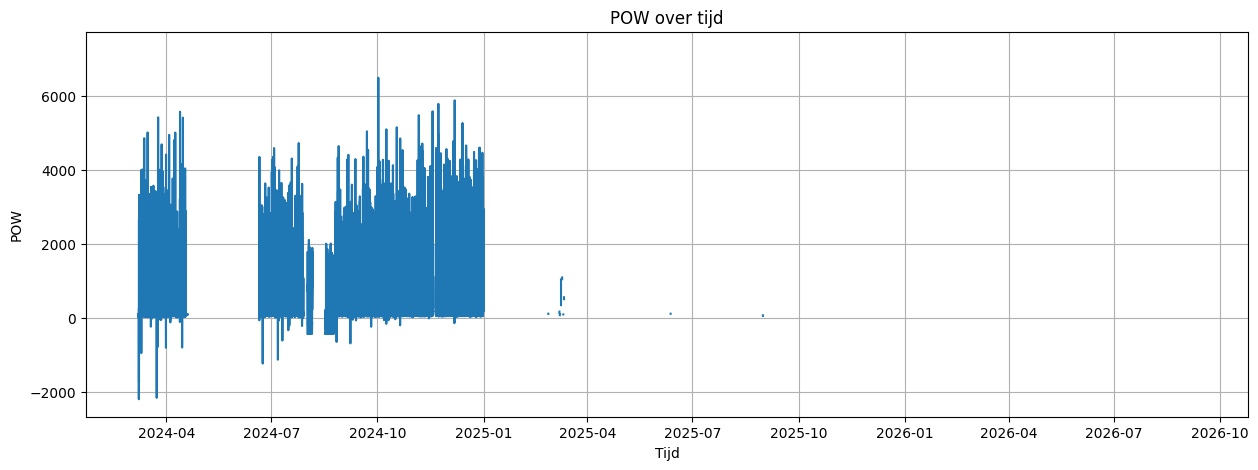

In [23]:
# Timestamp omzetten naar datetime
df_totaal["timestamp"] = pd.to_datetime(df_totaal["timestamp"])

# Sorteren op tijd
df_totaal = df_totaal.sort_values("timestamp")

# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_totaal["timestamp"], df_totaal["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [24]:
df_viermaanden = df_totaal[
    (df_totaal['timestamp'] > '2024-10-01') &
    (df_totaal['timestamp'] < '2025-01-01')
]

In [25]:
pow_leeg= df_viermaanden[df_viermaanden['POW'] < 0]
pow_leeg.head(5)

,timestamp,CO2,CTYPE,ENAME,ENE,EONNAME,ETYPE,GNAME,POW,CO2_IMP,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
36336,2024-10-06 13:50:00+02:00,3.315667,electricity,totaalverbruik-16eda211b788,22.866667,None,powermeter,None,-38.528302,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
36372,2024-10-06 16:50:00+02:00,1.352432,electricity,totaalverbruik-16eda211b788,9.729730,None,powermeter,None,-5.432990,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
36374,2024-10-06 17:00:00+02:00,0.027882,electricity,totaalverbruik-16eda211b788,0.200590,None,powermeter,None,-68.694118,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
36921,2024-10-08 15:25:00+02:00,2.688683,electricity,totaalverbruik-16eda211b788,5.883333,None,powermeter,None,-168.894737,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
37307,2024-10-10 12:30:00+02:00,0.180794,electricity,totaalverbruik-16eda211b788,1.349206,None,powermeter,None,-73.458333,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN


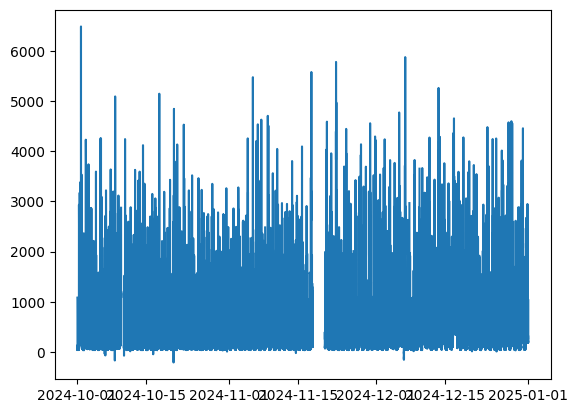

In [26]:
fig ,ax = plt.subplots()
plt.plot(df_viermaanden['timestamp'],df_viermaanden['POW'])
plt.show()

In [27]:
df_viermaanden_impute= df_viermaanden.interpolate(method='linear')

C:\Users\stijn\AppData\Local\Temp\ipykernel_26408\3238882189.py:1: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_viermaanden_impute= df_viermaanden.interpolate(method='linear')


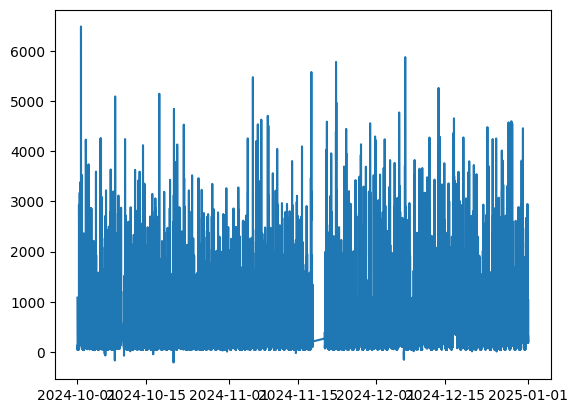

In [28]:
fig ,ax = plt.subplots()
plt.plot(df_viermaanden_impute['timestamp'],df_viermaanden_impute['POW'])
plt.show()

In [29]:
df_viermaanden_impute.to_parquet(OUTPUT_FILE)